# The Mixed Subjects Design
EOS Masterclass · 8 October 2026 · David Broska

We take one experiment from the TESS archive of Ashokkumar, Hewitt, Ghezae & Willer (2026, *Nature*) and estimate its treatment effect three ways: with **silicon subjects** (GPT-4 predictions only), with **human subjects** only, and with a **mixed subjects** design that combines both (prediction-powered inference, PPI).

## The experiment: Social pressure and party ratings (Connors 2023, *Public Opinion Quarterly*, Study 4)
- **Argument:** partisans see affective polarization (liking one's own party, disliking the other) as socially desirable, so some partisans may report stronger polarization than they actually feel.
- **Paper's design:** partisans in the AmeriSpeak panel (March 2020, via TESS; N = 1,895) were randomly told nothing (control), *"Just a reminder, the results based on your responses may be published"* (public), or *"Just a reminder, your responses are completely private"* (private), before rating both parties on 0-100 feeling thermometers.
- **Paper's findings:** average polarization (in-party minus out-party rating) did not differ across conditions, and the published reminder had no effect; the privacy reminder lowered reported polarization only among people who say they adjust their behavior to impress others, and only modestly.
- **Contrast used here:** a fourth arm that the paper sets aside "for other research" (fn. 13). In the TESS archive its wording is *"Imagine your friends will read your responses to the following questions"* (treatment); we compare it with no reminder (control).
- **Outcome (Y):** *"How would you rate Republicans?"* from 0 (cold) to 100 (warm), for all 1,620 respondents in these two arms, including independents. To keep the demonstration simple, we analyze only this one component of the paper's polarization measure.

In [1]:
# In Colab, first run:  !pip install ppi-python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ppi_py import classical_ols_ci, ppi_ols_ci, ppi_ols_power

## 1. Data
One row per participant:
- `treated`: 1 = treatment, 0 = control
- `Y`: the participant's actual answer (0-100)
- `Yhat`: GPT-4's predicted answer for a person with the same party, ideology, age, race, gender and education in the same condition (from the paper's simulated participants)

In [2]:
data = pd.read_csv("data/connors.csv")
data.head()

,treated,Y,Yhat
0,0,85,66.79
1,0,0,23.68
2,0,0,19.26
3,0,100,88.74
4,0,75,86.22


## 2. Human subjects and silicon subjects
Suppose we could afford to recruit only half of the 1,620 participants. For the other half, we use silicon subjects: GPT-4's predictions instead of their actual answers.

- **Human subjects** (`n`): a random half of the participants, whose answers we keep.
- **Silicon subjects** (`N`): the other half. We pretend their answers were never collected and keep only GPT-4's predictions.



In [3]:
np.random.seed(48)   # a typical split: estimates close to the full-sample effect, CI reduction at the median of 300 splits
human = np.random.rand(len(data)) < 0.5           # True for the half that are human subjects

X = np.column_stack([np.ones(len(data)), data["treated"]])   # intercept and treatment
Y = data["Y"].to_numpy()
Yhat = data["Yhat"].to_numpy()

X_human, Y_human, Yhat_human = X[human], Y[human], Yhat[human]
X_silicon, Yhat_silicon = X[~human], Yhat[~human]
n, N = human.sum(), (~human).sum()
print("human subjects n =", n, "| silicon subjects N =", N)

human subjects n = 804 | silicon subjects N = 816


## 3. Three estimates of the treatment effect
Each line regresses an outcome on treatment and returns a 95% confidence interval for the intercept and the treatment effect (`[1]`).

- The silicon subjects estimate compares GPT-4's predicted answers between treatment and control for the other half (no human answers).
- The human subjects estimate is what you would get by running the study with only half of the participants. 
- The mixed subjects estimate uses the same half plus GPT-4's predictions for the other half.

In [4]:
silicon = classical_ols_ci(X_silicon, Yhat_silicon, alpha=0.05)                    # GPT-4 predictions only
humans  = classical_ols_ci(X_human, Y_human, alpha=0.05)                           # human subjects only
mixed   = ppi_ols_ci(X_human, Y_human, Yhat_human, X_silicon, Yhat_silicon, alpha=0.05)  # both (PPI)

table = pd.DataFrame(
    [[ci[0][1], ci[1][1]] for ci in (silicon, humans, mixed)],
    index=["Silicon subjects", "Human subjects", "Mixed subjects"],
    columns=["lower", "upper"],
)
table["estimate"] = (table.lower + table.upper) / 2   # the intervals are symmetric
table["width"] = table.upper - table.lower
table.round(2)

,lower,upper,estimate,width
Silicon subjects,-0.31,7.18,3.44,7.49
Human subjects,0.45,9.09,4.77,8.63
Mixed subjects,1.01,8.53,4.77,7.51


**How do the estimates compare?** Relative to the human subjects estimate (4.8 points), GPT-4 alone gives a smaller effect (3.4 points), and its interval includes zero. The mixed subjects estimate does not have to equal the human subjects estimate, but here the two are almost identical (4.8).

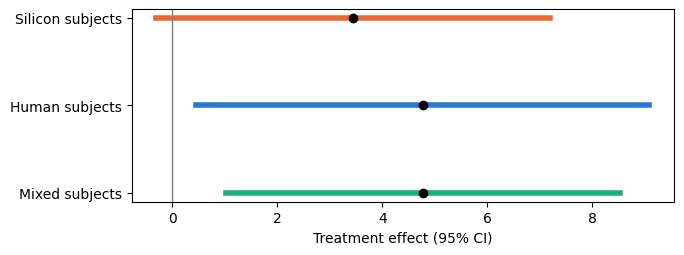

In [5]:
plt.figure(figsize=(7, 2.5))
for i, (name, row) in enumerate(table.iterrows()):
    plt.plot([row.lower, row.upper], [i, i], lw=4, color=["#eb6834", "#2a78d6", "#1baf7a"][i])
    plt.plot(row.estimate, i, "o", color="black")
plt.yticks(range(3), table.index)
plt.axvline(0, color="grey", lw=1)
plt.xlabel("Treatment effect (95% CI)")
plt.gca().invert_yaxis()
plt.show()

The mixed subjects estimate is more precise: its 95% interval is narrower than the human subjects interval, although both use the same 804 human answers. The gain comes from GPT-4's predictions for the other 816 participants, corrected by how far GPT-4 is off for the human subjects.

## 4. How much narrower is the mixed subjects interval?

In [6]:
reduction = 1 - table.width["Mixed subjects"] / table.width["Human subjects"]
print(f"The mixed subjects CI is {100 * reduction:.0f}% narrower than the human subjects CI.")

The mixed subjects CI is 13% narrower than the human subjects CI.


## 5. The gain is a function of the PPI correlation
The PPI correlation $\rho$ (Broska, Howes & van Loon 2025) measures how informative the predictions are about the parameter. With $n$ human and $N$ silicon subjects, the mixed subjects interval is narrower by about $1 - \sqrt{1 - \rho^2 N/(n+N)}$.

In [7]:
rho = ppi_ols_power(X_human, Y_human, Yhat_human, cost_X=0, cost_Y=1, cost_Yhat=0.01,
                    coord=1, effective_n=n)["ppi_corr"]
expected = 1 - np.sqrt(1 - rho**2 * N / (n + N))
print(f"PPI correlation: {rho:.2f}")
print(f"Expected reduction: {100 * expected:.0f}%   Observed reduction: {100 * reduction:.0f}%")

PPI correlation: 0.69
Expected reduction: 13%   Observed reduction: 13%


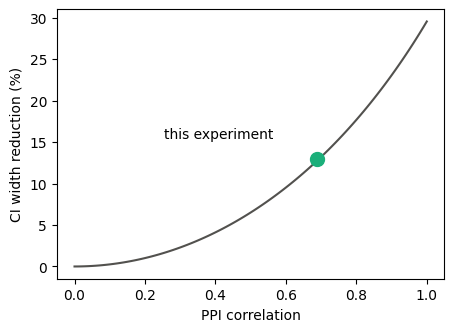

In [8]:
r = np.linspace(0, 1, 101)
plt.figure(figsize=(5, 3.5))
plt.plot(r, 100 * (1 - np.sqrt(1 - r**2 * N / (n + N))), color="#52514e")
plt.plot(rho, 100 * reduction, "o", color="#1baf7a", markersize=10)
plt.annotate("this experiment", (rho, 100 * reduction), xytext=(-110, 15), textcoords="offset points")
plt.xlabel("PPI correlation")
plt.ylabel("CI width reduction (%)")
plt.show()

The more predictive GPT-4 is, the higher the PPI correlation and the narrower the mixed subjects interval. The gain also grows with the share of silicon subjects, $N/(n+N)$.

**Note:** GPT-4's predictions are informative here, likely because ratings of Republicans differ mainly between Democrats and Republicans, which GPT-4 predicts well from the persona.